# Modelagem preditiva — dengue nas nove capitais do Nordeste

Este notebook ajusta modelos para casos semanais e para cruzamento do limiar MEM, com validação temporal walk-forward e horizonte de quatro semanas. Cada origem de treino usa apenas dados publicados até aquela semana. A base termina na semana epidemiológica 43 de 2026; previsões geradas a partir desse corte são condicionais à última semana publicada, não quatro semanas completas a partir da data de execução.

Os dados são públicos e documentados nas tabelas `fontes_dados_modelagem.csv` e `dicionario_modelagem.csv`. Casos vêm do InfoDengue, população do painel público DATASUS/SVS e clima diário NASA POWER agregado em semanas. NASA POWER é dado meteorológico em grade, não observação de uma estação local. A EDA anterior usou ERA5; esta etapa usa NASA POWER consistentemente no backtest. Nenhum dado sintético é usado.

Execute a partir do início. O script Python gera métricas, previsões, intervalos, gráficos e interpretação em `reports/modelagem_capitais/`.

In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'src' / 'model_capitais.py').exists():
    ROOT = Path.cwd().parent
assert (ROOT / 'src' / 'model_capitais.py').exists(), 'Abra o notebook dentro da pasta do projeto.'
sys.path.insert(0, str(ROOT))
print('Projeto:', ROOT)
panel_file = ROOT / 'data' / 'processed' / 'painel_capitais_modelagem.parquet'
if not panel_file.exists():
    raise FileNotFoundError('Base tratada ausente. Use data/processed/painel_capitais_modelagem.parquet incluída nesta entrega.')

# Pipeline completo: origens walk-forward, modelos, classificação MEM, DM e previsões finais.
subprocess.run([sys.executable, str(ROOT / 'src' / 'model_capitais.py'), '--n-origins', '24'], cwd=ROOT, check=True)
OUT = ROOT / 'reports' / 'modelagem_capitais'
TABLE = OUT / 'tables'
FIG = OUT / 'figures'

Projeto: C:\Users\Jp\Documents\ChatGPT\Projeto Final Disciplina _ Serie Temporais\entrega_professor


## Interpretação e decisões de modelagem

A interpretação abaixo explica a escolha de modelos, validação, métricas, limites e previsão. MAE e RMSE estão em casos por semana; MAPE usa somente semanas com casos positivos e informa a cobertura. O teste de Diebold–Mariano compara perdas fora da amostra; p acima de 0,05 significa que não há evidência suficiente de diferença, não que os modelos sejam iguais.

In [2]:
display(Markdown((OUT / 'interpretacao_modelagem.md').read_text(encoding='utf-8')))


# Modelagem e validação — nove capitais do Nordeste

## Dados e origem de previsão

A base de casos do InfoDengue foi atualizada em 09/11/2026 e contém observações até a SE 202643 (25/10/2026, início da semana epidemiológica), com **9 capitais** e **5,553 semanas-capital**. Clima diário NASA POWER foi agregado a semanas iniciadas no domingo; população vem do último ano conhecido no painel DATASUS, sem usar anos futuros. O corte local do modelo usa casos prováveis `casprov` e rótulo oficial `nivel_inc_mem == 2` para incidência acima do limiar MEM.

NASA POWER é uma fonte meteorológica em grade, não uma estação observacional local. O modelo usa NASA POWER de forma consistente em todo o período para temperatura (°C), precipitação acumulada semanal (mm) e umidade relativa (%). A EDA exploratória anterior usou reanálise ERA5 do pacote Mosqlimate; correlações dela são candidatas, enquanto a seleção final de variáveis será confirmada no backtest com as variáveis NASA. Fontes, períodos, unidades e transformações estão em `tables/fontes_dados_modelagem.csv` e `tables/dicionario_modelagem.csv`.

## Validação temporal

Foram usadas 24 origens expansivas entre 21/01/2024 e 27/09/2026, espaçadas ao longo dos últimos anos. Em cada origem, o treino usa somente semanas até aquela origem; nenhuma divisão aleatória é usada. Cada modelo prevê diretamente horizontes de 1 a 4 semanas, e as explicativas climáticas têm defasagem suficiente para estarem disponíveis no corte.

## Modelos e intervalos

1. Baseline sazonal: repete casos observados 52 semanas antes.
2. Binomial Negativa global: GLM de contagem com efeitos fixos de capital, exposição populacional e dispersão NB2 fixada em α=1; intervalos 90% pela distribuição binomial negativa.
3. SARIMAX sazonal local: ARMA(1,1) sobre log(1+casos), com dois pares de harmônicos Fourier anuais como regressoras sazonais; intervalos 90% do estado-espaço transformados para casos.
4. Random Forest global: árvores com efeitos de capital; intervalos 90% pelo pool empírico de valores nas folhas das árvores (aproximação de floresta quantílica).
5. LightGBM Poisson global: perda Poisson; intervalos 90% por regressões quantílicas nos níveis 5% e 95%.

Após uma comparação de especificações no mesmo walk-forward, todos os modelos globais usam temperatura como único preditor meteorológico. Para NB, entra um único lag por horizonte (mínimo 2 semanas); RF e LightGBM recebem lags de temperatura observados e disponíveis na origem. Precipitação e umidade foram excluídas da especificação principal porque não melhoraram o RMSE da NB e elevaram redundância entre preditores. A cobertura e largura dos intervalos são verificadas no walk-forward; a cobertura observada pode ficar abaixo dos 90% nominais.

## Resultados

O menor RMSE agregado foi de **Binomial Negativa global** (54.68 casos/semana); o segundo menor foi **SARIMAX sazonal** (59.23). A tabela completa com MAE, RMSE, MAPE apenas em semanas positivas, cobertura do MAPE, sMAPE e MASE está em `tables/metricas_modelos.csv`, por horizonte em `tables/metricas_por_horizonte.csv` e por capital em `tables/metricas_por_capital.csv`.

Como dengue tem zeros e contagens pequenas em parte das semanas, MAPE é reportado apenas onde casos observados >0 e vem acompanhado da cobertura; sMAPE e MASE completam a avaliação.

A ablation climática pareada está em `tables/comparacao_especificacoes_clima.csv`: NB com temperatura apenas teve RMSE 54,68; sem clima, 56,03; com temperatura, chuva e umidade, 55,55. O ganho é modesto, por isso temperatura fica como covariável candidata e a exclusão dos outros climas é mantida por parcimônia, não como prova de ausência de associação.

### Precisão de eventos MEM

O classificador LightGBM de cruzamento MEM (probabilidade ≥0,5) obteve precisão=0.635, recall=0.810 e F1=0.712 no conjunto de origens. O desbalanceamento e a escolha do limiar afetam esses números; a tabela também separa os quatro horizontes.

### Diebold–Mariano

Os dois modelos comparados são Binomial Negativa global e SARIMAX sazonal, escolhidos pela RMSE de validação, não por desempenho no treino. O teste usa diferença de perda quadrática regional, agregada por semana-alvo e horizonte, com variância HAC até lag 3 e correção de amostra finita. Resultados por horizonte estão em `tables/diebold_mariano.csv`; p>0,05 significa evidência insuficiente de diferença, não equivalência.

### SARIMAX

Ajustes SARIMAX concluídos: 216; falhas documentadas: 0. Ver `tables/diagnostico_sarimax.csv`; não foram substituídos silenciosamente por dados inventados.

## Previsão a partir do dado mais recente

O modelo selecionado por RMSE (Binomial Negativa global) gera previsões para **01/11/2026–22/11/2026**, correspondentes aos horizontes 1–4 a partir de 25/10/2026. O InfoDengue tem atraso de divulgação: na data de execução (09/11/2026), as primeiras semanas deste horizonte já podem ter começado ou terminado, embora a série pública ainda pare na SE 202643. Portanto, são previsões condicionadas à última semana publicada, não previsões em tempo real para quatro semanas completas a partir de hoje.

Os arquivos `tables/previsao_4_semanas_por_modelo.csv` e `tables/resumo_previsao_por_capital.csv` incluem casos, intervalo 90%, incidência por 100 mil habitantes e probabilidade estimada de ultrapassar o limiar MEM. Para previsão de incidência, o modelo não inventa um corte futuro: usa o classificador treinado no rótulo oficial MEM.

## Limitações e próximo passo

As origens de validação são 24 semanas escolhidas ao longo dos últimos ~145 períodos; a amostra temporal ainda limita o teste DM. A chuva da NASA é acumulada semanal em mm, enquanto a EDA ERA5 anterior usou taxa média em mm/h. O pipeline mantém fontes e unidades distintas documentadas.

Não se deve reutilizar previsões dos rascunhos antigos: esta análise foi recalculada para nove capitais com casos atualizados em novembro de 2026.

## Métricas de previsão de casos

Compare a tabela agregada com resultados por horizonte e por capital. A seleção por menor RMSE é uma regra operacional; confira também MAE, MASE, sMAPE e a adequação dos intervalos.

In [3]:
for name in ['metricas_modelos.csv', 'metricas_por_horizonte.csv', 'metricas_por_capital.csv', 'cobertura_intervalos.csv']:
    print('###', name)
    display(pd.read_csv(TABLE / name))

### metricas_modelos.csv


,modelo,MAE_casos_semana,RMSE_casos_semana,MAPE_pct_y_positivo,cobertura_MAPE_pct,sMAPE_pct,MASE,n_previsoes,zeros_observados
0,Binomial Negativa global,26.914983,54.681217,42.071363,99.652778,32.175451,0.250024,864,3
1,SARIMAX sazonal,26.502171,59.228868,34.203043,99.652778,30.170239,0.256438,864,3
2,LightGBM Poisson,29.092976,63.488992,42.145575,99.652778,31.452420,0.275972,864,3
3,Random Forest,30.107444,69.400309,41.142567,99.652778,31.333884,0.279435,864,3
4,Baseline sazonal,70.182870,125.175275,112.079314,99.652778,66.868451,0.638504,864,3


### metricas_por_horizonte.csv


,modelo,horizonte_semanas,MAE_casos_semana,RMSE_casos_semana,MAPE_pct_y_positivo,cobertura_MAPE_pct,sMAPE_pct,MASE,n_previsoes,zeros_observados
0,LightGBM Poisson,1,16.454673,26.241048,24.772078,99.537037,22.011117,0.157489,216,1
1,Binomial Negativa global,1,15.983291,26.716248,23.871637,99.537037,22.274898,0.152262,216,1
2,Random Forest,1,16.111771,27.535745,23.637450,99.537037,21.503947,0.156208,216,1
3,SARIMAX sazonal,1,16.417876,31.729682,21.436084,99.537037,21.638723,0.162595,216,1
4,Baseline sazonal,1,65.305556,116.181690,89.081528,99.537037,61.779350,0.596774,216,1
5,Binomial Negativa global,2,21.404451,39.236953,37.715090,100.000000,28.211916,0.203159,216,0
6,LightGBM Poisson,2,23.681368,43.517433,39.246080,100.000000,28.000738,0.226073,216,0
7,SARIMAX sazonal,2,22.394955,47.119457,30.832970,100.000000,26.504205,0.217339,216,0
8,Random Forest,2,25.508562,51.384093,36.514452,100.000000,27.626641,0.237206,216,0
9,Baseline sazonal,2,71.194444,129.579019,120.596221,100.000000,67.802445,0.644566,216,0


### metricas_por_capital.csv


,modelo,municipio,horizonte_semanas,MAE_casos_semana,RMSE_casos_semana,MAPE_pct_y_positivo,sMAPE_pct,n_previsoes
0,Baseline sazonal,Aracaju,1,13.250000,18.209430,138.347658,73.794731,24
1,Baseline sazonal,Aracaju,2,13.583333,18.389308,240.397269,88.167165,24
2,Baseline sazonal,Aracaju,3,12.833333,17.865236,137.917054,69.419746,24
3,Baseline sazonal,Aracaju,4,14.583333,18.677080,256.141202,89.167802,24
4,Baseline sazonal,Fortaleza,1,45.708333,59.682144,163.986532,82.360109,24
...,...,...,...,...,...,...,...,...
175,SARIMAX sazonal,São Luís,4,21.929538,34.078251,39.986189,48.288802,24
176,SARIMAX sazonal,Teresina,1,30.564163,63.044642,21.205491,19.216380,24
177,SARIMAX sazonal,Teresina,2,42.942714,98.665579,22.325928,25.272038,24
178,SARIMAX sazonal,Teresina,3,42.079068,78.491797,27.632534,29.957490,24


### cobertura_intervalos.csv


,modelo,horizonte_semanas,nivel_nominal_pct,cobertura_empirica_pct,largura_media_intervalo_casos,n
0,Baseline sazonal,1,90,94.907407,366.946065,216
1,Baseline sazonal,2,90,94.907407,370.396528,216
2,Baseline sazonal,3,90,94.907407,367.206713,216
3,Baseline sazonal,4,90,93.981481,365.755556,216
4,Binomial Negativa global,1,90,100.000000,283.648148,216
5,Binomial Negativa global,2,90,99.537037,281.425926,216
6,Binomial Negativa global,3,90,98.611111,287.833333,216
7,Binomial Negativa global,4,90,96.296296,294.666667,216
8,LightGBM Poisson,1,90,90.740741,73.291375,216
9,LightGBM Poisson,2,90,90.277778,100.335788,216


## Evento epidemiológico e comparação de modelos

A classificação MEM estima a probabilidade de incidência acima do limiar oficial do InfoDengue. Precisão, recall e F1 refletem o limiar de classificação 0,5. Diebold–Mariano é calculado por horizonte a partir da perda regional semanal dos dois melhores modelos por RMSE.

In [4]:
for name in ['metricas_evento_MEM.csv', 'diebold_mariano.csv', 'diagnostico_sarimax.csv']:
    print('###', name)
    display(pd.read_csv(TABLE / name))

### metricas_evento_MEM.csv


,horizonte_semanas,precision,recall,F1,limiar_probabilidade,n,eventos_MEM,prevalencia_pct
0,1,0.809524,0.894737,0.850000,0.5,216,38,17.592593
1,2,0.727273,0.888889,0.800000,0.5,216,36,16.666667
2,3,0.545455,0.727273,0.623377,0.5,216,33,15.277778
3,4,0.490196,0.714286,0.581395,0.5,216,35,16.203704
4,todos,0.635359,0.809859,0.712074,0.5,864,142,16.435185


### diebold_mariano.csv


,horizonte_semanas,modelo_A,modelo_B,diferenca_perda_quadratica_A_menos_B,estatistica_DM_HAC,p_valor_bilateral,origens_temporais,lag_HAC,interpretacao
0,1,Binomial Negativa global,SARIMAX sazonal,-293.014784,-1.600936,0.123038,24,3,"p<0,05 indica diferença de perda pareada; não ..."
1,2,Binomial Negativa global,SARIMAX sazonal,-680.704754,-1.367093,0.184810,24,3,"p<0,05 indica diferença de perda pareada; não ..."
2,3,Binomial Negativa global,SARIMAX sazonal,-580.977784,-1.112150,0.277564,24,3,"p<0,05 indica diferença de perda pareada; não ..."
3,4,Binomial Negativa global,SARIMAX sazonal,-517.395743,-0.701395,0.490093,24,3,"p<0,05 indica diferença de perda pareada; não ..."


### diagnostico_sarimax.csv


,geocode,municipio,status,aic,convergiu,especificacao,avisos,origin
0,2111300,São Luís,ok,708.921067,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2024-01-21
1,2211001,Teresina,ok,564.438728,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2024-01-21
2,2304400,Fortaleza,ok,190.892722,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2024-01-21
3,2408102,Natal,ok,339.401439,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2024-01-21
4,2507507,João Pessoa,ok,202.606510,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2024-01-21
...,...,...,...,...,...,...,...,...
211,2507507,João Pessoa,ok,173.487374,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2026-09-27
212,2611606,Recife,ok,208.240112,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2026-09-27
213,2704302,Maceió,ok,638.508988,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2026-09-27
214,2800308,Aracaju,ok,841.477592,True,"SARIMAX ARMA(1,1) com 2 harmônicos Fourier anu...",NaN,2026-09-27


## Gráficos de avaliação e previsões

Os gráficos mostram erro por horizonte, cobertura dos intervalos e previsão por capital. Intervalos largos expressam incerteza; previsão de incidência usa população conhecida e probabilidade de cruzamento do MEM usa o classificador.

01_rmse_por_horizonte.png


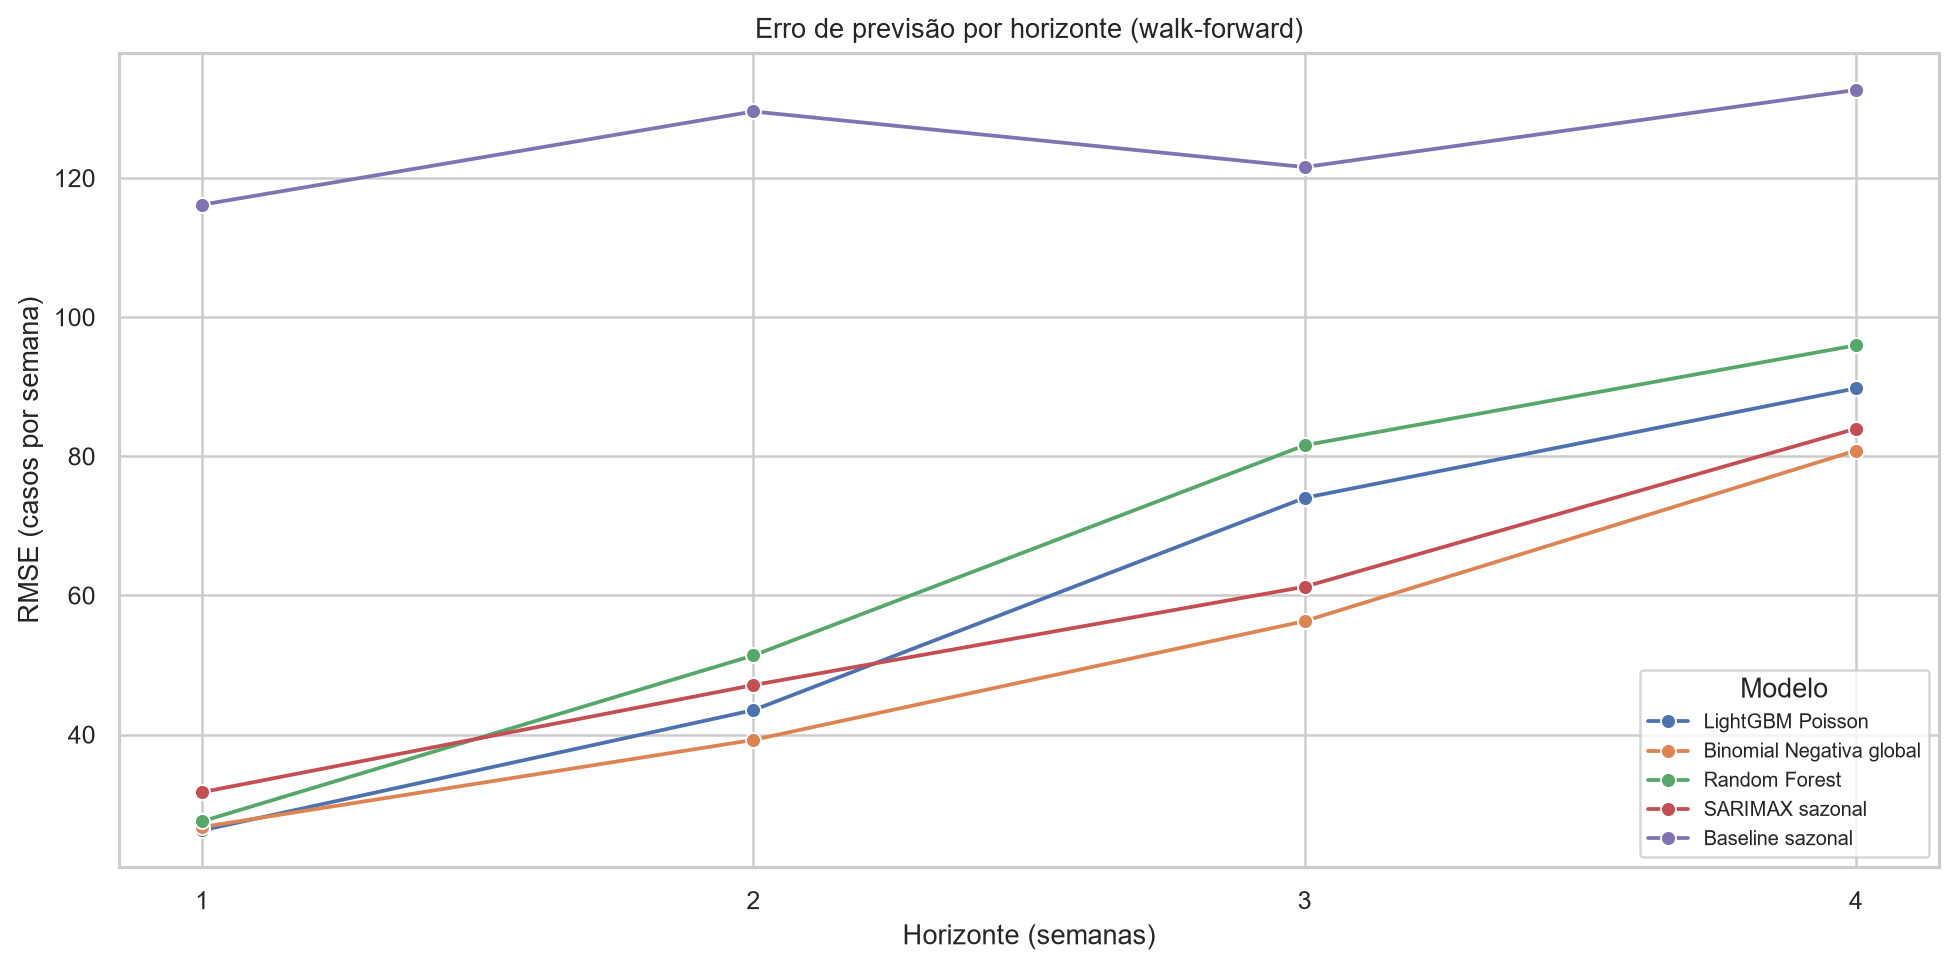

02_cobertura_intervalos.png


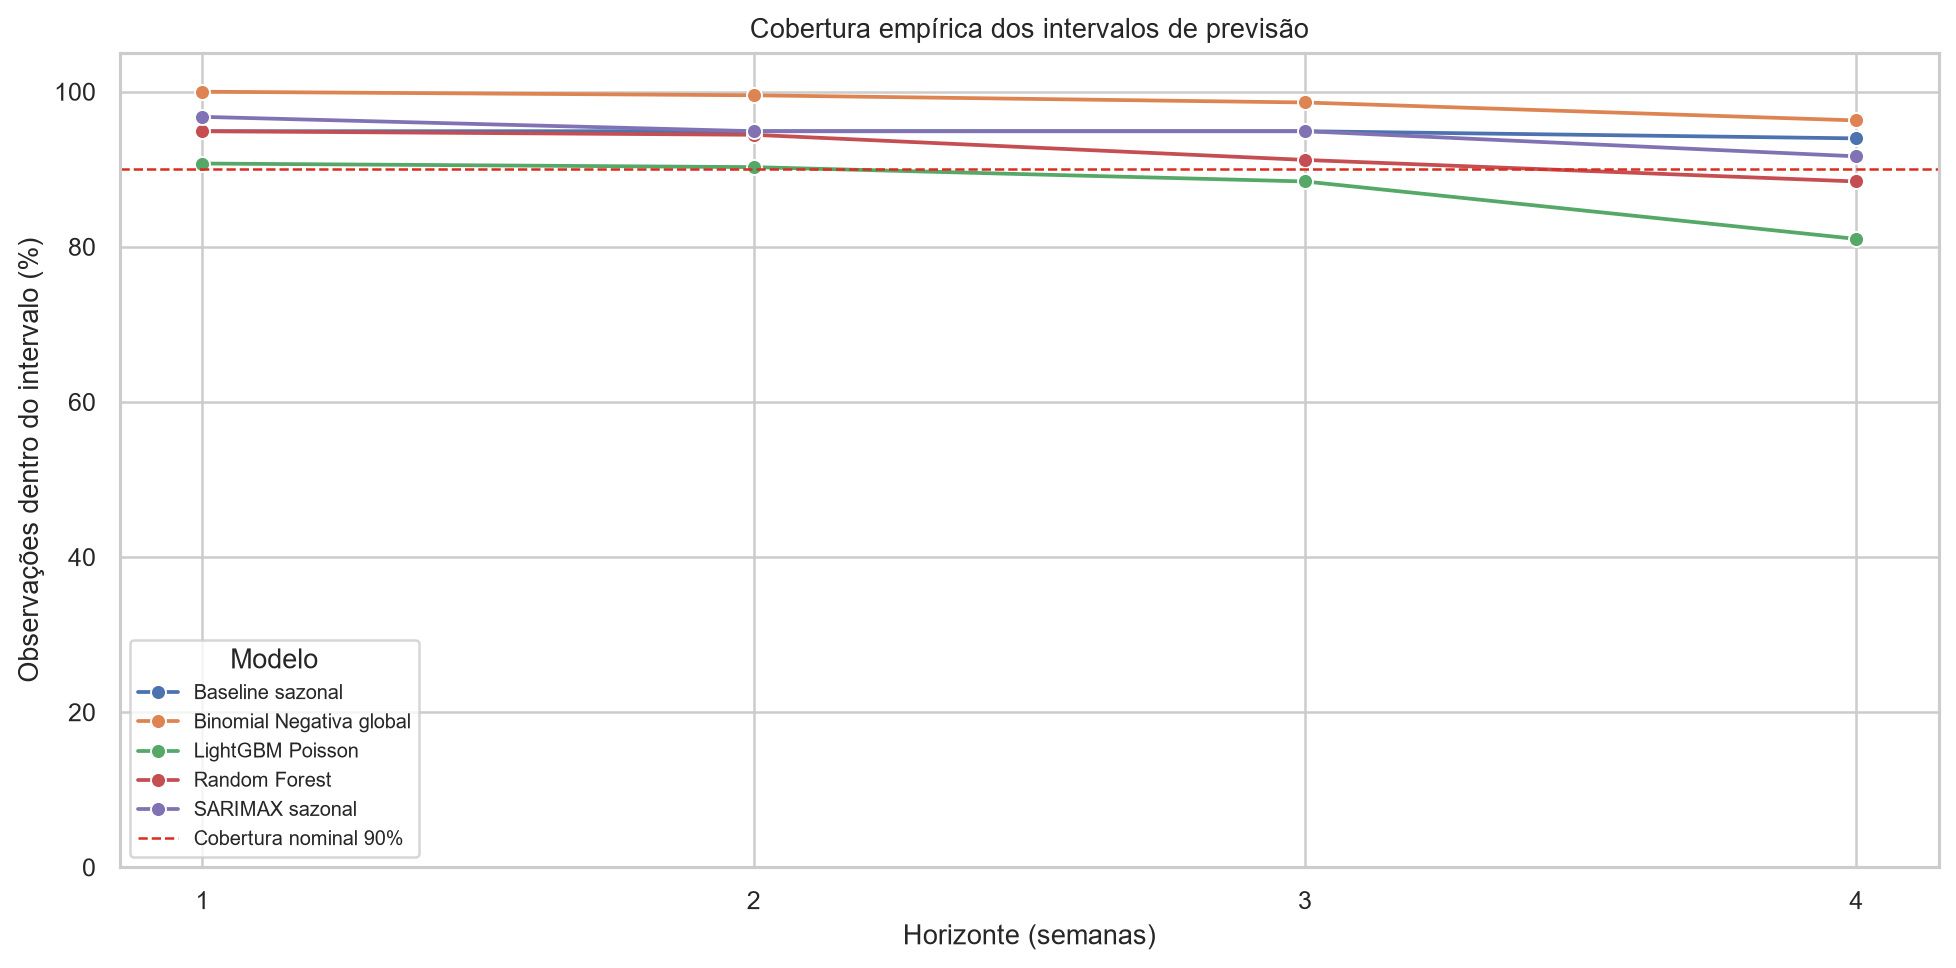

03_previsao_proximas_4_semanas.png


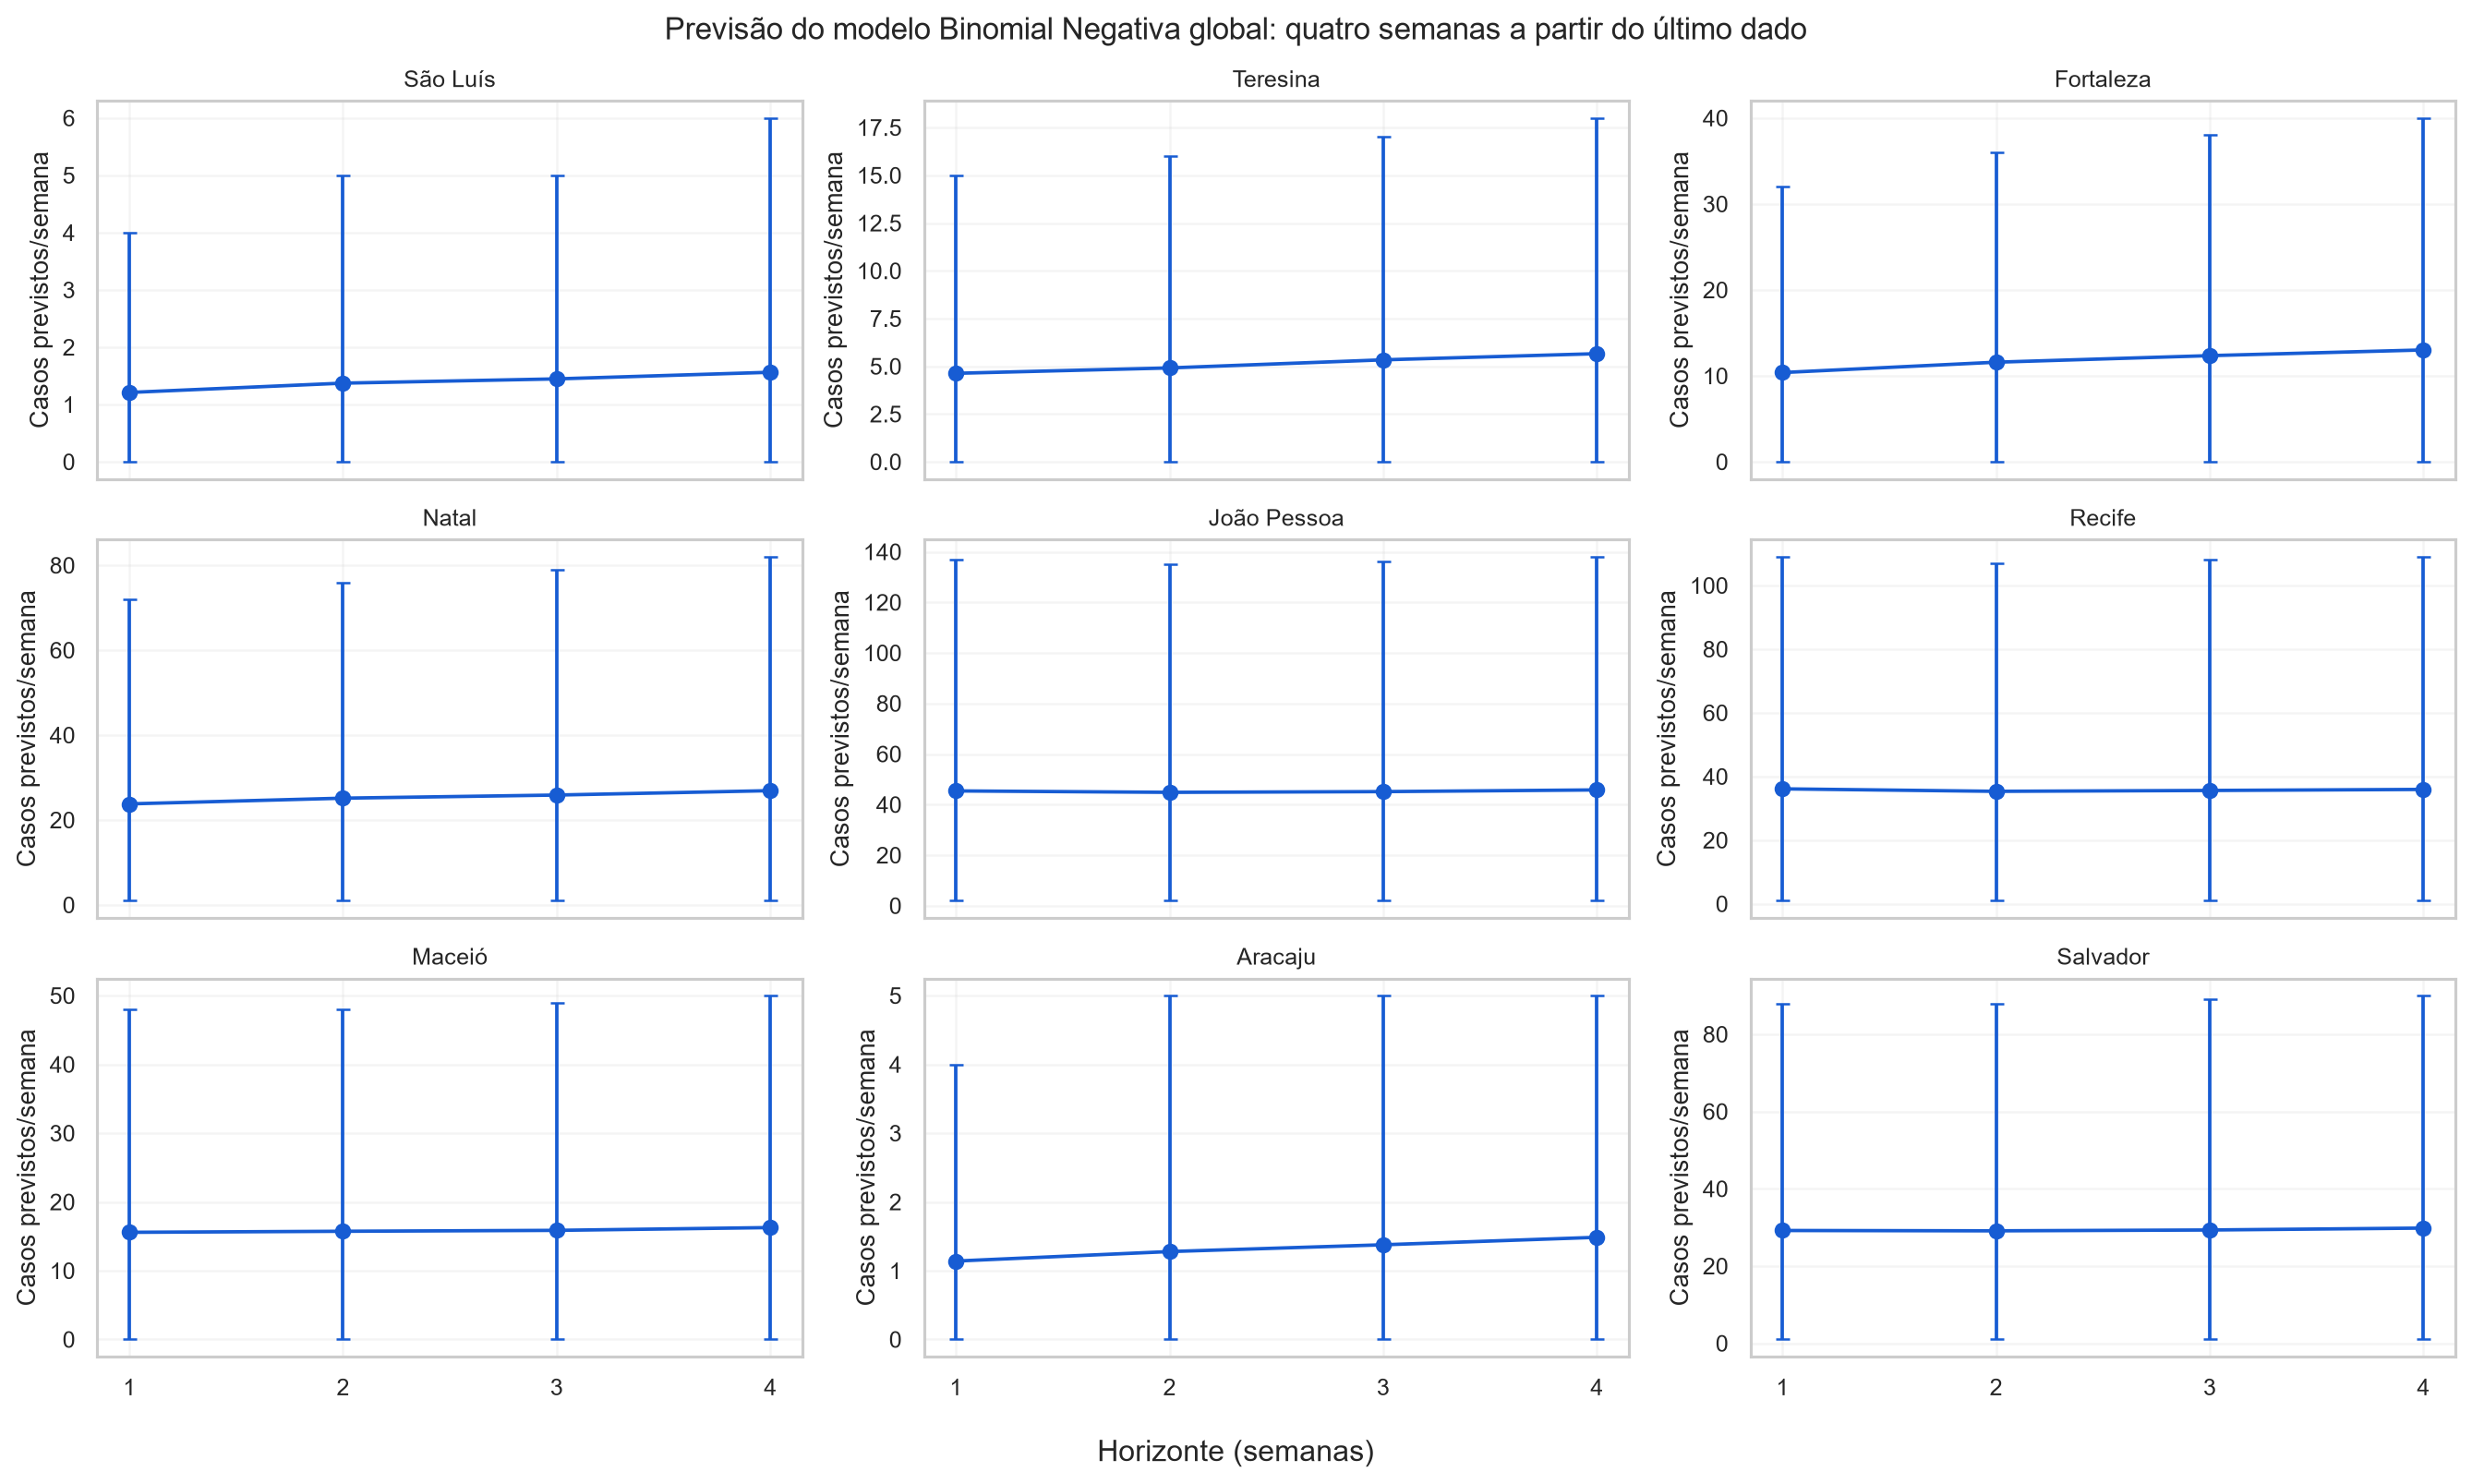

04_ablation_clima_rmse.png


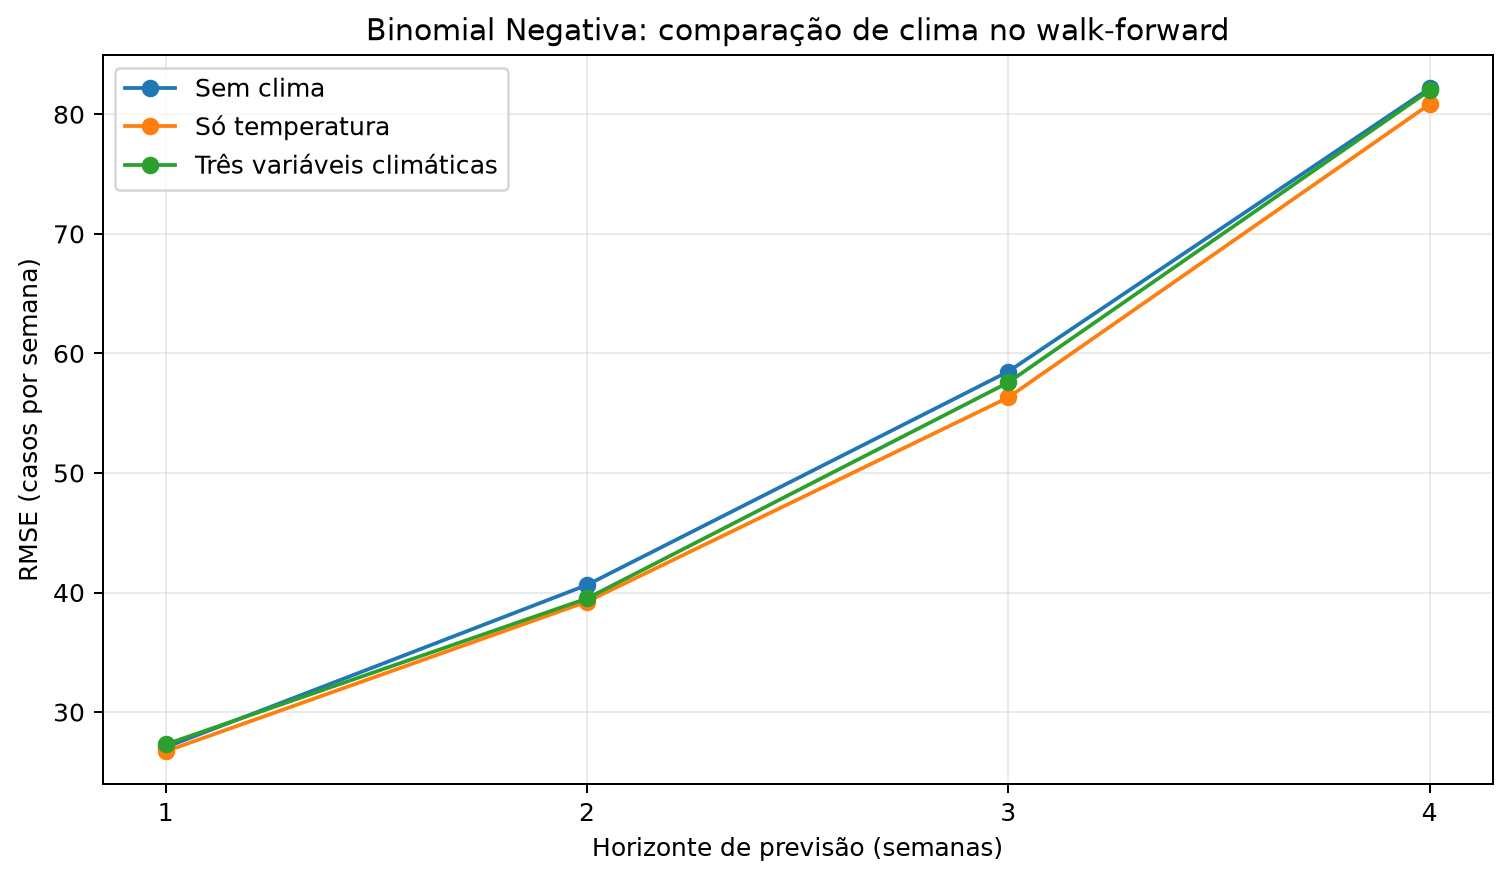

In [5]:
for p in sorted(FIG.glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

## Previsão final

A tabela apresenta as previsões por capital para os quatro horizontes, com intervalos de 90%, incidência por 100 mil habitantes e probabilidade estimada de ultrapassar MEM. O corte de casos publicado pode estar defasado em relação à data corrente; use as datas de origem e alvo ao interpretar os números.

In [6]:
display(pd.read_csv(TABLE / 'resumo_previsao_por_capital.csv'))
display(pd.read_csv(TABLE / 'resumo_previsao_regional.csv'))
display(pd.read_csv(TABLE / 'fontes_dados_modelagem.csv'))
display(pd.read_csv(TABLE / 'dicionario_modelagem.csv'))

,geocode,municipio,uf,target_date,population,origin,horizon,model,casos_previstos,limite_90_inferior,limite_90_superior,incidencia_prevista_100mil,probabilidade_acima_limiar_MEM,alerta_MEM_prob_ge_0_5
0,2111300,São Luís,MA,2026-11-01,1089215.0,2026-10-25,1,Binomial Negativa global,1.210949,0.0,4.0,0.111176,0.227597,False
1,2211001,Teresina,PI,2026-11-01,905692.0,2026-10-25,1,Binomial Negativa global,4.635131,0.0,15.0,0.511778,0.001436,False
2,2304400,Fortaleza,CE,2026-11-01,2578483.0,2026-10-25,1,Binomial Negativa global,10.388126,0.0,32.0,0.402877,0.001170,False
3,2408102,Natal,RN,2026-11-01,784249.0,2026-10-25,1,Binomial Negativa global,23.800061,1.0,72.0,3.034758,0.004341,False
4,2507507,João Pessoa,PB,2026-11-01,897633.0,2026-10-25,1,Binomial Negativa global,45.409101,2.0,137.0,5.058760,0.003522,False
5,2611606,Recife,PE,2026-11-01,1588376.0,2026-10-25,1,Binomial Negativa global,36.118587,1.0,109.0,2.273932,0.003748,False
6,2704302,Maceió,AL,2026-11-01,994952.0,2026-10-25,1,Binomial Negativa global,15.583154,0.0,48.0,1.566222,0.006180,False
7,2800308,Aracaju,SE,2026-11-01,630932.0,2026-10-25,1,Binomial Negativa global,1.140317,0.0,4.0,0.180735,0.001746,False
8,2927408,Salvador,BA,2026-11-01,2564204.0,2026-10-25,1,Binomial Negativa global,29.208283,1.0,88.0,1.139078,0.008947,False
9,2111300,São Luís,MA,2026-11-08,1089215.0,2026-10-25,2,Binomial Negativa global,1.373458,0.0,5.0,0.126096,0.039172,False


,target_date,origin,horizon,casos_previstos_total,limite_90_inferior_soma,limite_90_superior_soma,populacao_total,probabilidade_media_MEM,incidencia_prevista_100mil
0,2026-11-01,2026-10-25,1,167.493709,5.0,509.0,12033736.0,0.028743,1.391868
1,2026-11-08,2026-10-25,2,169.357606,5.0,516.0,12033736.0,0.007039,1.407357
2,2026-11-15,2026-10-25,3,172.361014,5.0,526.0,12033736.0,0.009209,1.432315
3,2026-11-22,2026-10-25,4,176.494171,5.0,538.0,12033736.0,0.013023,1.466661


,variavel,fonte,periodo,documentacao,observacoes
0,casos prováveis e MEM,InfoDengue alertcity,2015–SE43 2026,https://info.dengue.mat.br/services/api,Consulta pública por geocódigo; último retorno...
1,"temperatura, chuva e umidade",NASA POWER Daily Point API,2015-01-01 a 2026-11-09,https://power.larc.nasa.gov/docs/services/api/...,"Grade NASA POWER; T2M, PRECTOTCORR, RH2M agreg..."
2,população,DATASUS/SVS via pacote de dados Mosqlimate,2001–2025; último ano conhecido,https://sprint.mosqlimate.org/data/,Última estimativa conhecida por semana; sem da...


,variavel,descricao,fonte,unidade,frequencia,uso
0,geocode,Código municipal IBGE,InfoDengue/IBGE,código,município,Efeito fixo/categórico de capital
1,date,Domingo de início da semana epidemiológica,InfoDengue,data,semanal,Índice temporal
2,casprov,Casos prováveis (suspeitos menos descartados),InfoDengue/SINAN/IBGE,casos,semanal,Alvo de regressão
3,surto_mem,1 se nível_inc MEM = 2 (incidência acima do li...,InfoDengue/MEM,0/1,semanal,Alvo de classificação
4,population,"População anual mais recente conhecida, carreg...",DATASUS/SVS,habitantes,anual,Exposição NB e cálculo da incidência
5,temp_med,Temperatura média diária agregada por semana,NASA POWER T2M,°C,semanal,Explicativa climática
6,precip_tot_mm,Soma semanal de precipitação corrigida diária,NASA POWER PRECTOTCORR,mm/semana,semanal,Explicativa climática
7,rel_humid_med,Umidade relativa média diária agregada por semana,NASA POWER RH2M,%,semanal,Explicativa climática
8,casos_lag_k,Casos prováveis k semanas antes,Calculada por capital após ordenar por data,casos,"semanal, k=1..8 e 52",Explicativas conhecidas na origem
9,clima_lag_k,Clima observado k semanas antes,Calculada por capital após ordenar por data,unidade da variável climática,"semanal, k=2..8",Só entram lags disponíveis no horizonte
